# Chapter 9 Multiagents: Sequential

## 1. Multi-Agent architecture

- Sequential: each agent is executed in sequence, one after the other
- Concurrent: Agnets can handle subtasks concurrently and aggregate their results
- Hybird: Execute independent tasks concurrently, while executing tasks with dependencies sequentially

## 2. ScenicMind(Sequentil)

### 2.1 Abstract

ScenicMind is a system for predicting the flow of vistros and analyzing operation in scenic areas.  
Its main workflow is : registration/login → upload daily visitor flow data → FlowStack model forecasting → dynamic data dashboard → Agent-generated business reports.

| Part | Technology | Responsibilities |
|---|---|---|
| Frontend | React 19 + TypeScript + Vite | Registration, upload, dashboard, Agent report page, AgentChat conversation |
| Backend | FastAPI + SQLite | Authentication, file storage, forecasting and analysis APIs; analysis results are stored as JSON in the `analyses` table |
| Data Service | pandas + FlowStack forecasting model (falls back to `SeasonalLagFallback` if loading fails) | Visitor flow forecasting, business metrics for 8 major modules, feature contribution |
| Agent Report Module | Pure Python orchestration, using `urllib` to call OpenAI-compatible APIs | The part to be reproduced in this lesson |

### 2.2 Design 

**Constraints -> Principles -> Practices:**
- The data is already structured: No RAG, use determinstic tools to fetch data directly
- Numbers in the reposrt must be trustworthy: The data package is the single source of truth. All roles only see the same compressed data package, and the prompt requires that all numeric values must come from the data package
- Separate reasoning from expression: The Analyst outputs only structured key points (insights, risks, actions), and the Writer is only responsible for turning them into a report. This makes it possible to check the analysis independently, and changing the writing style does not affect the analysis
- The page must not go blank → If any LLM call step fails, fall back to a template report and assemble a deterministic brief from pure data
- Report generation takes tens of seconds → The API immediately returns 202; a background thread generates the report, and the frontend polls the progress of each stage
- The three report types have different requirements → Use the same pipeline and switch the Analyst and Writer prompts by report type

**Why sequential: Each step depends on the output of the previous step: routing → data fetching → analysis → writing → review. The steps are fixed and there are only five, so a straight line is the simplest and easiest to debug.**

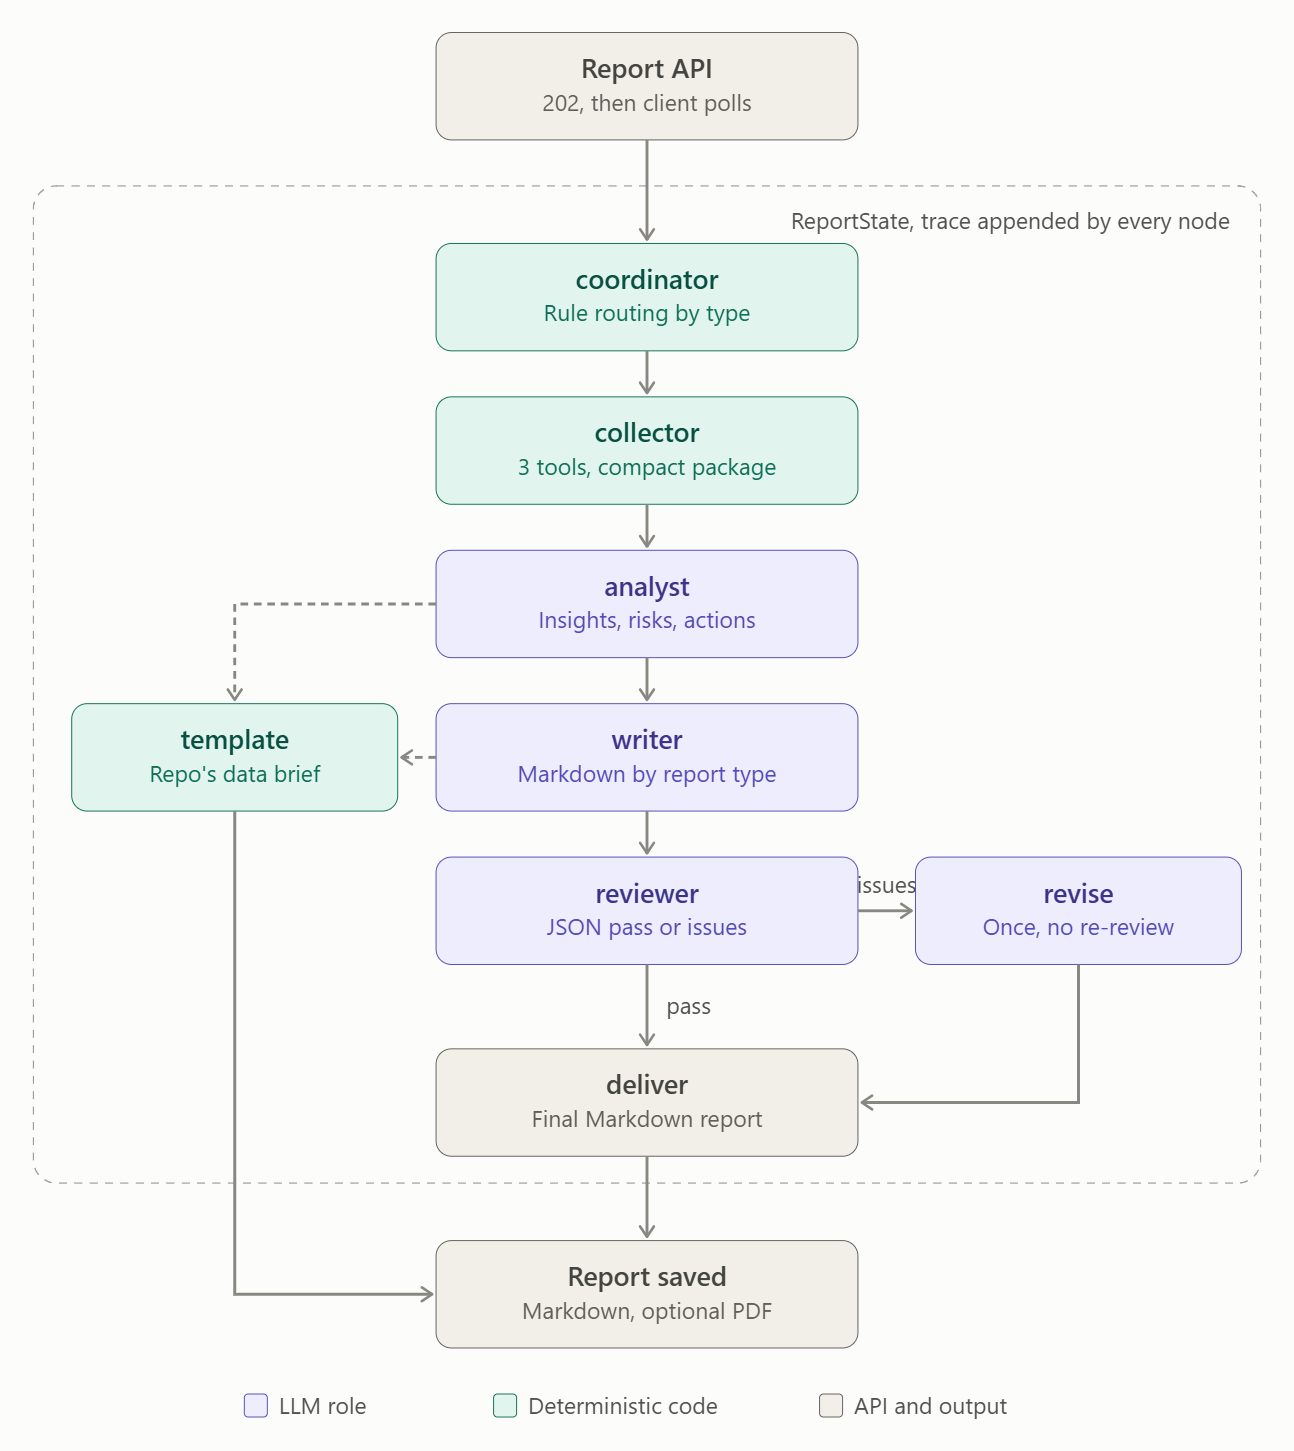

### Prepare the environment

In [1]:
import json
import operator
import os
import re
import sys
import threading
import time
from datetime import datetime
from pathlib import Path
from typing import Annotated, Literal, TypedDict

from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from pydantic import BaseModel, ConfigDict, Field

LANGUAGE = "English"          # "Chinese" reproduces the original reports word for word

load_dotenv()                                    # finds the .env in the repo root
REPO = (Path.cwd().parent / "Project" / "ScenicMind" / "ScenicMind").resolve()   # git clone https://github.com/vacucity/ScenicMind Project/ScenicMind
RUNTIME = Path.cwd() / "scenicmind_runtime"
os.environ["SCENICMIND_RUNTIME_DIR"] = str(RUNTIME)   # keep runtime files out of your repo
sys.path.insert(0, str(REPO / "backend"))

from app.agent import prompts, tools                     # your prompts and tool layer, unchanged
from app.agent.graph import _compact_data, _template_report
from app.database import json_dumps
from app.services.dataset import normalize_dataset, read_uploaded_dataset
from app.services.forecast import analyze_visitors
from app.services.indicators import compute_indicators

# the data side of ScenicMind: one completed analysis built from the repo's sample CSV
CSV = REPO / "sample_daily_visitors.csv"
data, warnings = normalize_dataset(read_uploaded_dataset(CSV))
result, importance = analyze_visitors(data, CSV.name, warnings)
ROW = {"status": "completed", "stored_path": str(CSV), "result_json": json_dumps(result),
       "importance_json": json_dumps(importance), "indicators_json": json_dumps(compute_indicators(data))}
tools.analysis_by_id = lambda analysis_id, user_id: ROW   # in-memory patch: the tools read this row instead of SQLite

llm = ChatOpenAI(model=os.getenv("LLM_MODEL_ID", "deepseek-flash"), api_key=os.getenv("LLM_API_KEY"),
                 base_url=os.getenv("LLM_BASE_URL"), temperature=0.3, timeout=90, max_retries=2, max_tokens=4000,
                 extra_body={"thinking": {"type": "disabled"}})
print(f"{len(data)} days of data | latest actual {result['latestActual']} | forecast points {len(result['forecastPoints'])}")

42 days of data | latest actual {'date': '2026-06-11', 'visitors': 3097} | forecast points 30


### The Contracts of different agents and context compresses

**Contracts**: Analysis and Review is the JSON structure mentioned in the original prompts. Using Pydantic to fix it. Review use alias='pass' since pass is the keyword in python, not used as a variable name.
**Context**: _compact_data compresses the dta package from 2,455 characters to 1,162 characters

In [2]:
class Insight(BaseModel):
    title: str
    detail: str = Field(description="Analysis with numbers taken from the data package")
    evidence: str = Field(description="Name of the data package field this insight relies on")


class Risk(BaseModel):
    title: str
    detail: str
    severity: Literal["high", "medium", "low"]


class Action(BaseModel):
    title: str
    detail: str
    when: str = Field(description="Trigger condition for the action")


class Analysis(BaseModel):
    """Analyst -> Writer contract (the original asks for this JSON shape in its prompt)."""
    insights: list[Insight]
    risks: list[Risk]
    actions: list[Action]


class Issue(BaseModel):
    type: str = Field(description="number mismatch, missing section or vague action")
    detail: str


class Review(BaseModel):
    """Reviewer contract: exactly the JSON the repo's REVIEWER_SYSTEM asks for, {"pass": bool, "issues": [...]}."""
    model_config = ConfigDict(populate_by_name=True)
    passed: bool = Field(alias="pass")
    issues: list[Issue] = []


LANG_RULE = f"\n\nWrite all output in {LANGUAGE}, including headings. Keep the required section structure."
TYPE_LABEL = {"daily_brief": "daily brief", "deep_dive": "deep dive", "periodic": "periodic report"}

NUMBER = re.compile(r"(?<![0-9A-Za-z_.])(\d{1,3}(?:,\d{3})+|\d+)(?:\.(\d+))?")


def untraceable_numbers(markdown: str, package: dict) -> list[str]:
    """Quality card only (not part of the original flow): numbers in the report that are not in the package."""
    known = {round(abs(float(n)), 2) for n in re.findall(r"\d+(?:\.\d+)?", json.dumps(package))}
    out = []
    for m in NUMBER.finditer(re.sub(r"\d{4}-\d{2}-\d{2}", " ", markdown)):
        v = float(m.group(0).replace(",", ""))
        if not (v <= 31 and v.is_integer()) and not any(abs(v - k) <= max(0.01 * k, 0.051) for k in known):
            out.append(m.group(0))
    return out


raw = tools.collect_all("demo", 1)
compact = _compact_data(raw)
print(f"raw package {len(json.dumps(raw, ensure_ascii=False))} chars -> compact package {len(compact)} chars sent to the LLM")
print("compact keys:", {k: list(v) if isinstance(v, dict) else type(v).__name__ for k, v in json.loads(compact).items()})

raw package 2455 chars -> compact package 1162 chars sent to the LLM
compact keys: {'forecast': ['latestActual', 'nextForecast', 'horizons', 'metrics'], 'indicators': ['visitorTrend', 'capacity', 'weather', 'dataQuality'], 'importance': ['semantic_groups'], 'gaps': 'list'}


### Five roles, review, delivery and degrading

In [3]:
class ReportState(TypedDict, total=False):
    analysis_id: str
    report_type: str
    question: str | None
    period: str | None
    data: dict                                   # full package, kept for the template fallback
    package: str                                 # compact package: what every LLM role sees
    analysis: dict
    draft: str
    review: dict
    final: str
    degraded: str | None
    trace: Annotated[list, operator.add]         # every role appends one entry; nothing is overwritten


def step(stage: str, status: str, detail: str = "") -> dict:
    return {"trace": [{"stage": stage, "status": status, "detail": detail, "time": datetime.now().strftime("%H:%M:%S")}]}


def coordinator(s: ReportState) -> dict:
    """Rule-based routing: the report type picks the prompt set (strategy pattern)."""
    if s["report_type"] not in prompts.ANALYST_SYSTEMS:
        raise ValueError(f"unsupported report type {s['report_type']}")
    return step("coordinator", "done", f"type {s['report_type']}, period {s.get('period') or '-'}, "
                                       f"topic {s.get('question') or 'general'}")


def collector(s: ReportState) -> dict:
    """Deterministic: three tools read stored JSON, missing pieces become gaps instead of errors."""
    package = tools.collect_all(s["analysis_id"], 1)
    return {"data": package, "package": _compact_data(package),
            **step("collector", "done", f"forecast, indicators, importance collected; {len(package['gaps'])} gaps")}


def analyst(s: ReportState) -> dict:
    user = f"Data package:\n{s['package']}\n"
    if s["report_type"] == "periodic" and s.get("period"):
        user += f"Reporting period: {s['period']} days.\n"
    if s.get("question"):
        user += f"Focus question: {s['question']}\n"
    try:
        a = llm.with_structured_output(Analysis, method="function_calling").invoke(
            [("system", prompts.ANALYST_SYSTEMS[s["report_type"]] + LANG_RULE), ("user", user)])
        if a is None:                                    # the model answered without calling the schema tool
            raise ValueError("no structured output")
    except Exception as e:
        return {"degraded": f"analyst {type(e).__name__}", **step("analyst", "failed", type(e).__name__)}
    return {"analysis": a.model_dump(),
            **step("analyst", "done", f"{len(a.insights)} insights, {len(a.risks)} risks, {len(a.actions)} actions")}


def writer(s: ReportState) -> dict:
    user = (f"Report type: {TYPE_LABEL[s['report_type']]}\n"
            + (f"Focus topic: {s['question']}\n" if s.get("question") else "")
            + f"Analysis points:\n{json.dumps(s['analysis'], ensure_ascii=False)}\n\n"
            f"Data package summary:\n{s['package']}\n\nWrite the report.")
    try:
        text = llm.invoke([("system", prompts.WRITER_SYSTEMS[s["report_type"]] + LANG_RULE), ("user", user)]).content
    except Exception as e:
        return {"degraded": f"writer {type(e).__name__}", **step("writer", "failed", type(e).__name__)}
    return {"draft": text, **step("writer", "done", f"{len(text)} chars")}


def reviewer(s: ReportState) -> dict:
    """JSON mode, like the original chat_json; a failed review is recorded, not hidden."""
    try:
        r = llm.with_structured_output(Review, method="json_mode").invoke(
            [("system", prompts.REVIEWER_SYSTEM + LANG_RULE),
             ("user", f"Data package:\n{s['package']}\n\nReport to review:\n{s['draft']}\n\nReview it and answer in JSON.")])
    except Exception as e:
        return {"review": None, **step("reviewer", "failed", f"{type(e).__name__}, delivered unreviewed")}
    detail = "approved" if r.passed else f"{len(r.issues)} issues, revising once"
    return {"review": r.model_dump(), **step("reviewer", "done" if r.passed else "revise", detail)}


def revise(s: ReportState) -> dict:
    """The original: rewrite once with the issues, then deliver without another review."""
    user = (f"The previous report failed review. Issues: {json.dumps(s['review']['issues'], ensure_ascii=False)}\n"
            f"Analysis points: {json.dumps(s['analysis'], ensure_ascii=False)}\nData package: {s['package']}\n"
            "Fix the issues and rewrite the report.")
    try:
        text = llm.invoke([("system", prompts.WRITER_SYSTEMS[s["report_type"]] + LANG_RULE), ("user", user)]).content
    except Exception as e:
        return {"degraded": f"revise {type(e).__name__}", **step("reviewer", "failed", type(e).__name__)}
    return {"draft": text, **step("reviewer", "done", "revised once, delivered with review notes")}


def deliver(s: ReportState) -> dict:
    return {"final": s["draft"]}


def template(s: ReportState) -> dict:
    """Never a blank page: a deterministic brief built from the data alone (the repo's own function)."""
    md = _template_report(s["data"], s["report_type"], s.get("question"), s.get("period"))
    return {"final": md, **step("llm", "degraded", f"{s['degraded']} -> template report")}


print("roles:", [f.__name__ for f in (coordinator, collector, analyst, writer, reviewer, revise, deliver, template)])

roles: ['coordinator', 'collector', 'analyst', 'writer', 'reviewer', 'revise', 'deliver', 'template']


### Sequential map

In [4]:
from langgraph.graph import END, START, StateGraph


def after(next_node: str):
    """Every LLM step either continues or falls back to the template."""
    return lambda s: "template" if s.get("degraded") else next_node


b = StateGraph(ReportState)
for fn in (coordinator, collector, analyst, writer, reviewer, revise, deliver, template):
    b.add_node(fn.__name__, fn)
b.add_edge(START, "coordinator")
b.add_edge("coordinator", "collector")
b.add_edge("collector", "analyst")
b.add_conditional_edges("analyst", after("writer"), ["writer", "template"])
b.add_conditional_edges("writer", after("reviewer"), ["reviewer", "template"])


def after_review(s: ReportState) -> str:
    if not s.get("review") or s["review"]["passed"]:
        return "deliver"
    return "revise"


b.add_conditional_edges("reviewer", after_review, ["deliver", "revise"])
b.add_conditional_edges("revise", after("deliver"), ["deliver", "template"])
b.add_edge("deliver", END)
b.add_edge("template", END)
report_agent = b.compile()
print("edges:", [(e.source, e.target) for e in report_agent.get_graph().edges if not e.source.startswith("__")])

edges: [('analyst', 'template'), ('analyst', 'writer'), ('collector', 'analyst'), ('coordinator', 'collector'), ('reviewer', 'deliver'), ('reviewer', 'revise'), ('revise', 'deliver'), ('revise', 'template'), ('writer', 'reviewer'), ('writer', 'template'), ('deliver', '__end__'), ('template', '__end__')]


### Generate a report

In [5]:
def show(result: dict):
    for t in result["trace"]:
        print(f"  {t['time']}  {t['stage']:<12}{t['status']:<9}{t['detail']}")


t0 = time.perf_counter()
report = report_agent.invoke({"analysis_id": "demo", "report_type": "deep_dive",
                              "question": "Is weekend capacity a risk, and what should we prepare?"})
print(f"deep dive finished in {time.perf_counter() - t0:.1f}s")
show(report)
print("\nquality card: untraceable numbers", untraceable_numbers(report["final"], json.loads(report["package"])))
print("\n" + report["final"][:700])

RUNTIME.mkdir(exist_ok=True)
(RUNTIME / "report_deep_dive.md").write_text(report["final"], encoding="utf-8")
try:
    from app.agent.pdf import markdown_to_pdf
    (RUNTIME / "report_deep_dive.pdf").write_bytes(markdown_to_pdf(report["final"]))
    print("saved report_deep_dive.md and .pdf in", RUNTIME)
except ModuleNotFoundError as e:
    print(f"saved report_deep_dive.md in {RUNTIME} (PDF export skipped: pip install {e.name})")

deep dive finished in 51.5s
  15:14:31  coordinator done     type deep_dive, period -, topic Is weekend capacity a risk, and what should we prepare?
  15:14:31  collector   done     forecast, indicators, importance collected; 0 gaps
  15:14:49  analyst     done     6 insights, 3 risks, 4 actions
  15:14:56  writer      done     6041 chars
  15:15:22  reviewer    failed   LengthFinishReasonError, delivered unreviewed

quality card: untraceable numbers ['8.6', '2.9', '9.9', '3.4', '1.18', '1.26', '8.6', '1.2', '1.3', '4492', '37', '34.5', '12.3', '1.18', '1.26', '12.3', '1.18', '1.26', '1.26', '35', '50', '6000', '1.2', '1.3', '35', '34.5', '1.2', '1.3']

# Deep Dive Business Analysis Report
## Weekend Capacity Risk Assessment and Preparation Plan

---

## I. Trend Insights

The near-term trend is **flat-to-slightly-up, not a surge**. The 7-day forecast averages 3186 visitors/day against the latest actual of 3097 (2026-06-11) and a 42-day historical average of 2934 — only +8.6% above the

### Simulate a real API — generate in the background, poll from the frontend

In [6]:
progress = {"status": "running", "last": None, "result": None}


def submit(inputs: dict) -> str:
    """POST /agent/report: start the job in a background thread and return immediately (HTTP 202)."""
    def run():
        final = {}
        for update in report_agent.stream(inputs, stream_mode="values"):
            final = update
            if final.get("trace"):
                progress["last"] = final["trace"][-1]
        progress["result"], progress["status"] = final, "done"
    threading.Thread(target=run, daemon=True).start()
    return "report-1"


report_id = submit({"analysis_id": "demo", "report_type": "daily_brief"})
print(f"POST /agent/report -> 202, report_id={report_id}")
seen = None
while progress["status"] == "running":                # GET /agent/report/{id}: the client polls
    last = progress["last"]
    if last and last != seen:
        print(f"  poll: {last['stage']} {last['status']}  {last['detail']}")
        seen = last
    time.sleep(0.5)
brief = progress["result"]
print("done:", [line for line in brief["final"].splitlines() if line.startswith("#")])
print("deep dive headings:", [line for line in report["final"].splitlines() if line.startswith("#")][:7])

POST /agent/report -> 202, report_id=report-1
  poll: collector done  forecast, indicators, importance collected; 0 gaps
  poll: analyst done  3 insights, 2 risks, 3 actions
  poll: writer done  2023 chars
  poll: reviewer revise  14 issues, revising once
done: ['# Daily Business Brief', "## 1. Today's Core Data", '## 2. Anomaly Alerts', "## 3. Today's Actions"]
deep dive headings: ['# Deep Dive Business Analysis Report', '## Weekend Capacity Risk Assessment and Preparation Plan', '## I. Trend Insights', '## II. Attribution Analysis', '## III. Key Findings', '## IV. Risks and Opportunities', '## V. Action Recommendations']


### Degrading if the service is not avaliable

In [7]:
good_llm = llm
llm = ChatOpenAI(model="x", api_key="x", base_url="http://127.0.0.1:9/v1", timeout=3, max_retries=0)   # provider down
try:
    down = report_agent.invoke({"analysis_id": "demo", "report_type": "daily_brief"})
    show(down)
    print("\n" + down["final"][:300])
finally:
    llm = good_llm

  15:16:16  coordinator done     type daily_brief, period -, topic general
  15:16:16  collector   done     forecast, indicators, importance collected; 0 gaps
  15:16:18  analyst     failed   OpenAIConnectionError
  15:16:18  llm         degraded analyst OpenAIConnectionError -> template report

# 每日经营简报（数据简报）

> 注：AI 分析服务暂不可用，以下为基于数据的确定性简报。

## 一、客流预测概要
- 最新真实客流：**3097 人**（2026-06-11）
- 下一日预测：**2914 人**（2026-06-12）
- 未来 7 天日均：**3186 人**，区间 2914–3771 人
- 模型回测：MAPE 5.1%，MAE 156.42 人

## 二、关键发现
- 客流同比变化 **None%**，环比 **None%**
- 平均载客率 **24.5%**，售罄 — 天，限流 — 天
- 节假日效应提升 **—%**（节假日日均 — vs 平日 —）
-


### Key results
- Core output: Cell 5 and Cell 6 generated two reports with different structures. The Deep Analysis has 5 chapters, while the Daily Brief has 3 chapters. They use the same pipeline and only switch prompts — this is the Strategy pattern.

- Complete execution trace: Each stage has a timestamp, status, and description. The original version stored progress in the database’s trace_json and overwrote it with the latest entry each time; here it was changed to append-only, so the entire chain is visible.

- The LLM reviewer requests revisions every time: The Deep Analysis reported 10 issues, and the Daily Brief reported 15. This is consistent with what was measured in Chapter 13: “even clean reports were all sent back.” Each revision adds another call, and the extra latency and cost are spent on an unreliable judgment.

- The data card reveals the original version’s real weakness: In the revised Deep Analysis, there are still 8 numbers whose sources cannot be found in the data package. 
  - These are ratios and percentages calculated by the model itself. Some of them are actually correct — for example, 5.6 means “the latest visitor flow is 5.6% higher than the average” — but they cannot be verified against the data package. 
  - The original version does not re-review after revision, so these numbers are delivered directly.

- This is exactly the problem the improved version aims to solve: calculate derived metrics in code, verify numbers in code, and combine this with a capped revision loop.

- The fallback report is the repository’s built-in Chinese template: It contains None% because the sample data only covers 42 days, so year-over-year and period-over-period comparisons cannot be calculated. This is the behavior of _template_report in the repository itself; the template has no fallback for missing fields.

- PDF was skipped: The repository uses reportlab to export PDFs, but it is not installed in the hello-agents environment. To enable it, run pip install reportlab and then run Cell 5 again.